# Evaluation of Teacher Ideological Estimation Methods

This notebook systematically evaluates and compares the performance of different LLM teacher supervision methods from `data/out/eval`:
1. **Pairwise Ranking (`Q_RANKING`)**: Teacher estimates the directional probability that Video A is more right-leaning than Video B. Video-level continuous ideological coordinates are derived using the **Elo rating system**.
2. **Absolute Scoring (`Q_ABSOLUTE`)**: Teacher directly grades ideological placement on a 5-level rubric (Far-Left to Far-Right) normalized to $[-1.0, +1.0]$.
3. **Pairwise Alignment (`Q_ALIGNMENT`)**: Teacher assesses ideological similarity/opposition between video pairs. 1D ideological coordinates are recovered via **Spectral Graph Embedding**.
4. **Context Ablation**: Every method is evaluated under two conditions:
   - **`context`**: Model receives video metadata + structured LLM video analysis (`analysis_json`).
   - **`no_context`**: Model receives raw video metadata only (Title, Channel, Tags).

### Benchmark:
All methods are benchmarked against **4,152 human pairwise comparisons** from `data/human_labels/human_labels.pkl`, evaluating accuracy, classification metrics, and logistic regression agreement curves matching the methodology in `pca.ipynb`.


In [1]:
import sys
from pathlib import Path

ROOT = Path("../")
sys.path.insert(0, str(ROOT / "src"))

import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from scipy.linalg import eigh
from sklearn.metrics import classification_report, accuracy_score, f1_score
from elo_rating import Elo

from config import DATA_DIR, OUT_DIR

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120


## 1. Load Evaluation Datasets & Ground Truth Human Labels


In [2]:
# Locate evaluation data directory
eval_dir = DATA_DIR / "out" / "eval" / "gpt-4o-mini-jev"
if not eval_dir.exists():
    eval_dir = DATA_DIR / "out" / "eval"

# Load ground-truth human annotations and video metadata
human_labels = pd.read_pickle(DATA_DIR / "human_labels" / "human_labels.pkl")
vid_metadata = pl.read_parquet(DATA_DIR / "human_labels" / "vid_metadata.parquet").to_pandas()

print(f"Human labels count: {len(human_labels):,} pairwise judgments")
print(f"Unique videos evaluated: {vid_metadata['id'].nunique():,}")
display(human_labels[["unique_ID", "category_name", "top_video_id", "bottom_video_id", "human_label"]].head(5))


Human labels count: 4,152 pairwise judgments
Unique videos evaluated: 2,382


,unique_ID,category_name,top_video_id,bottom_video_id,human_label
0,1025,Indicate which video is more liberal,5HK1hFUD_d4,QPVA8HH7l1w,bot
1,1112,Indicate which video is more liberal,npAKW_HPnq8,AK4_ogsh0Po,top
2,1029,Indicate which video is more liberal,Ib1nTc7859Y,_TgcOISrlqE,bot
3,1061,Indicate which video is more liberal,KC-JiXnQSUA,JkxW7ecWl-o,bot
4,1070,Indicate which video is more liberal,SvjTeuSKTW0,iEWqEtnLLEo,bot


## 2. Pairwise Ranking — Elo Rating Computation
For the ranking condition, the teacher answers:
`"Is video A more right-leaning than video B on an overall/economic/cultural ideology scale?"`

Using the **Elo rating system** (`from elo_rating import Elo`), we treat each video pair as an ideological matchup where the teacher's probability serves as the match result. Videos acquire a continuous ideological rating:
* **Higher Elo**: Consistently evaluated as more conservative / right-leaning.
* **Lower Elo**: Consistently evaluated as more liberal / left-leaning.


In [3]:
# Compute Elo ratings across all ranking datasets (Context vs No Context, across 3 ideological axes)
elo_ratings = {}

for ctx in ["context", "no_context"]:
    rank_path = eval_dir / f"{ctx}_ranking.parquet"
    df_rank = pl.read_parquet(rank_path).to_pandas()
    
    for dim in ["overall", "economic", "cultural"]:
        col = f"is_more_right_leaning_{dim}"
        elo = Elo(denom=1.0)
        for _, row in df_rank.iterrows():
            prob = float(row[col])
            elo.add_match(row["id_a"], row["id_b"], result=prob, k=0.1)
            
        key = f"ranking_{ctx}_{dim}"
        elo_ratings[key] = elo.ratings()
        print(f"Computed Elo ratings for {key} across {len(elo.ratings()):,} videos.")


Computed Elo ratings for ranking_context_overall across 2,382 videos.
Computed Elo ratings for ranking_context_economic across 2,382 videos.
Computed Elo ratings for ranking_context_cultural across 2,382 videos.
Computed Elo ratings for ranking_no_context_overall across 2,382 videos.
Computed Elo ratings for ranking_no_context_economic across 2,382 videos.
Computed Elo ratings for ranking_no_context_cultural across 2,382 videos.


### Elo Rating Distributions
Distribution of learned Elo ideological coordinates across the three dimensions (Overall, Economic, Cultural), comparing Context against No Context.


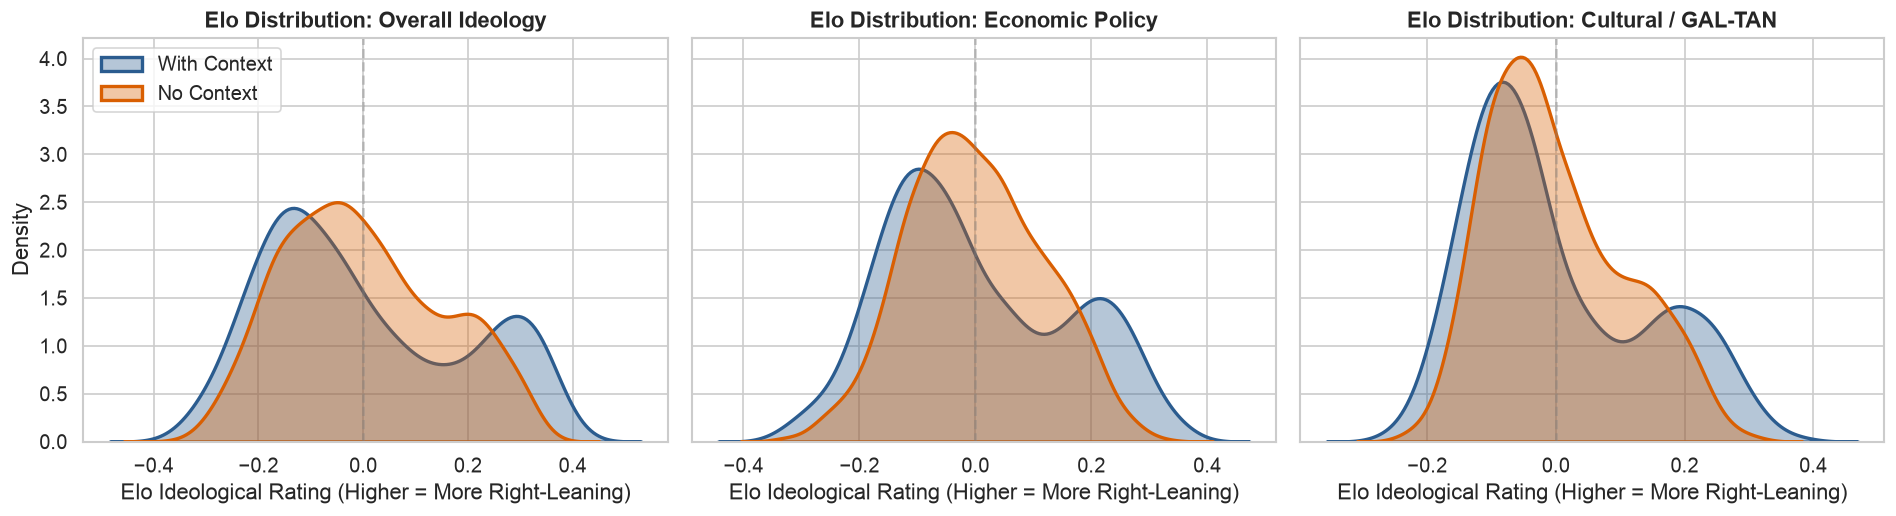

In [4]:
# Plot Elo Rating distributions for Context vs No-Context across all 3 dimensions
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
dims = [("overall", "Overall Ideology"), ("economic", "Economic Policy"), ("cultural", "Cultural / GAL-TAN")]

for idx, (dim, title) in enumerate(dims):
    ctx_vals = list(elo_ratings[f"ranking_context_{dim}"].values())
    no_ctx_vals = list(elo_ratings[f"ranking_no_context_{dim}"].values())
    
    sns.kdeplot(ctx_vals, ax=axes[idx], label="With Context", color="#2b5c8f", fill=True, alpha=0.35, linewidth=2.0)
    sns.kdeplot(no_ctx_vals, ax=axes[idx], label="No Context", color="#d95f02", fill=True, alpha=0.35, linewidth=2.0)
    
    axes[idx].set_title(f"Elo Distribution: {title}", fontsize=13, fontweight="bold")
    axes[idx].set_xlabel("Elo Ideological Rating (Higher = More Right-Leaning)")
    axes[idx].axvline(0, color="grey", linestyle="--", alpha=0.4)
    if idx == 0:
        axes[idx].legend(loc="upper left")

plt.tight_layout()
plt.show()


## 3. Absolute Scoring & Spectral Alignment Embeddings
* **Absolute Scoring (`Q_ABSOLUTE`)**: Aggregates the teacher's direct $[-1.0, +1.0]$ ideological scores per video.
* **Pairwise Alignment (`Q_ALIGNMENT`)**: Recovers continuous 1D ideological coordinates from pairwise similarity using the Fiedler vector (second smallest eigenvector of the graph Laplacian).


In [5]:
# 1. Aggregate Absolute Scores per video (Context vs No Context)
absolute_scores = {}
for ctx in ["context", "no_context"]:
    abs_path = eval_dir / f"{ctx}_absolute.parquet"
    df_abs = pl.read_parquet(abs_path).to_pandas()
    for dim, col in [("overall", "overall_score"), ("economic", "economic_score"), ("cultural", "galtan_score")]:
        score_dict = df_abs.groupby("id_a")[col].mean().to_dict()
        absolute_scores[f"absolute_{ctx}_{dim}"] = score_dict

# 2. Extract 1D Ideological Axis from Alignment Graphs via Spectral Embedding (Fiedler Vector)
alignment_scores = {}
for ctx in ["context", "no_context"]:
    align_path = eval_dir / f"{ctx}_alignment.parquet"
    df_align = pl.read_parquet(align_path).to_pandas()
    vids = sorted(list(set(df_align["id_a"]).union(set(df_align["id_b"]))))
    vid2idx = {v: i for i, v in enumerate(vids)}
    n = len(vids)
    
    W = np.zeros((n, n))
    for _, row in df_align.iterrows():
        i, j = vid2idx[row["id_a"]], vid2idx[row["id_b"]]
        aff = (float(row["overall_ideological_alignment"]) + 1.0) / 2.0
        W[i, j] = max(W[i, j], aff)
        W[j, i] = max(W[j, i], aff)
        
    D = np.diag(W.sum(axis=1) + 1e-6)
    L = D - W
    _, vecs = eigh(L, D)
    fiedler = vecs[:, 1]
    alignment_scores[f"alignment_spectral_{ctx}_overall"] = {vids[i]: float(fiedler[i]) for i in range(n)}

print(f"Extracted absolute scores and spectral alignment coordinates.")


Extracted absolute scores and spectral alignment coordinates.


<Axes: ylabel='Count'>

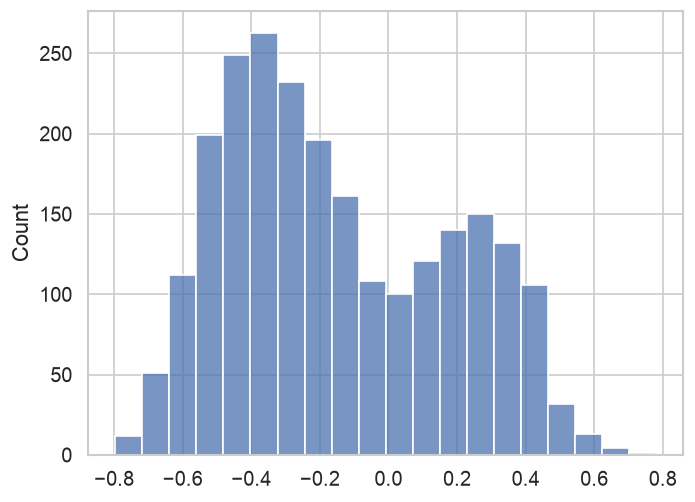

In [12]:
sns.histplot(data=absolute_scores["absolute_context_overall"])

## 4. Benchmark Against Human Labelers (Methodology from `pca.ipynb`)
For each model and evaluation method:
1. Map video scores to `top_video_score` and `bottom_video_score` for all 4,152 human pairwise comparisons.
2. Form directional predictions:
   - If `category_name == "Indicate which video is more conservative"`:
     - Predict `"top"` if `top_score > bottom_score`, else `"bot"`.
   - If `category_name == "Indicate which video is more liberal"`:
     - Predict `"bot"` if `top_score > bottom_score`, else `"top"`.
3. Compute Agreement, Accuracy, Macro F1, and evaluate agreement probability as a function of ideological distance.


In [6]:
def evaluate_scores_against_human_labels(score_dict, name):
    df_eval = human_labels.copy()
    df_eval["top_score"] = df_eval["top_video_id"].map(score_dict)
    df_eval["bot_score"] = df_eval["bottom_video_id"].map(score_dict)
    df_eval = df_eval.dropna(subset=["top_score", "bot_score"]).copy()
    
    def pred(r):
        if r["category_name"] == "Indicate which video is more conservative":
            return "top" if r["top_score"] > r["bot_score"] else "bot"
        else:
            return "bot" if r["top_score"] > r["bot_score"] else "top"
            
    df_eval["pred_label"] = df_eval.apply(pred, axis=1)
    df_eval["agree"] = df_eval["pred_label"] == df_eval["human_label"]
    df_eval["dist"] = (df_eval["top_score"] - df_eval["bot_score"]).abs()
    
    acc = accuracy_score(df_eval["human_label"], df_eval["pred_label"])
    f1_macro = f1_score(df_eval["human_label"], df_eval["pred_label"], average="macro")
    
    return {
        "method_key": name,
        "n_evaluated": len(df_eval),
        "accuracy": acc,
        "f1_macro": f1_macro,
        "df_eval": df_eval
    }

# Benchmark all methods
all_evaluations = {}
for k, scores in elo_ratings.items():
    all_evaluations[k] = evaluate_scores_against_human_labels(scores, k)

for k, scores in absolute_scores.items():
    all_evaluations[k] = evaluate_scores_against_human_labels(scores, k)

for k, scores in alignment_scores.items():
    e_pos = evaluate_scores_against_human_labels(scores, k)
    neg_scores = {vid: -val for vid, val in scores.items()}
    e_neg = evaluate_scores_against_human_labels(neg_scores, k)
    all_evaluations[k] = e_pos if e_pos["accuracy"] >= e_neg["accuracy"] else e_neg

# Format master comparison table
summary_rows = []
for k, res in all_evaluations.items():
    parts = k.split("_")
    method_family = parts[0].title()
    ctx_type = "Context" if "context" in k and "no_context" not in k else "No Context"
    dim_name = parts[-1].title()
    summary_rows.append({
        "Method": f"{method_family} ({'Elo' if method_family == 'Ranking' else 'Spectral' if method_family == 'Alignment' else 'Direct'})",
        "Context": ctx_type,
        "Dimension": dim_name,
        "Valid Pairs": res["n_evaluated"],
        "Accuracy (%)": round(res["accuracy"] * 100, 2),
        "Macro F1": round(res["f1_macro"], 4)
    })

summary_table = pd.DataFrame(summary_rows).sort_values("Accuracy (%)", ascending=False).reset_index(drop=True)
display(summary_table)


,Method,Context,Dimension,Valid Pairs,Accuracy (%),Macro F1
0,Ranking (Elo),Context,Overall,4139,70.21,0.7020
1,Ranking (Elo),Context,Economic,4139,70.02,0.7001
2,Absolute (Direct),No Context,Overall,4139,69.80,0.6980
3,Ranking (Elo),Context,Cultural,4139,69.56,0.6956
4,Absolute (Direct),No Context,Cultural,4139,69.39,0.6938
5,Absolute (Direct),Context,Cultural,4139,69.22,0.6921
6,Absolute (Direct),Context,Overall,4139,69.12,0.6912
7,Absolute (Direct),No Context,Economic,4139,68.66,0.6866
8,Ranking (Elo),No Context,Overall,4139,68.23,0.6823
9,Ranking (Elo),No Context,Cultural,4139,67.96,0.6796


### Classification Reports for Best Models
Detailed precision, recall, and F1 performance for the top-performing models in each family.


In [7]:
print("=== Best Ranking Model: Ranking (Elo) with Context (Overall) ===")
print(classification_report(
    all_evaluations["ranking_context_overall"]["df_eval"]["human_label"],
    all_evaluations["ranking_context_overall"]["df_eval"]["pred_label"]
))

print("\n=== Best Absolute Model: Absolute without Context (Overall) ===")
print(classification_report(
    all_evaluations["absolute_no_context_overall"]["df_eval"]["human_label"],
    all_evaluations["absolute_no_context_overall"]["df_eval"]["pred_label"]
))


=== Best Ranking Model: Ranking (Elo) with Context (Overall) ===
              precision    recall  f1-score   support

         bot       0.70      0.70      0.70      2046
         top       0.70      0.71      0.71      2093

    accuracy                           0.70      4139
   macro avg       0.70      0.70      0.70      4139
weighted avg       0.70      0.70      0.70      4139


=== Best Absolute Model: Absolute without Context (Overall) ===
              precision    recall  f1-score   support

         bot       0.69      0.70      0.70      2046
         top       0.70      0.70      0.70      2093

    accuracy                           0.70      4139
   macro avg       0.70      0.70      0.70      4139
weighted avg       0.70      0.70      0.70      4139



## 5. Comparative Visualizations
### Model Accuracy Comparison: Context vs. No Context
Compare how the presence of structured LLM video context affects accuracy across evaluation paradigms and dimensions.


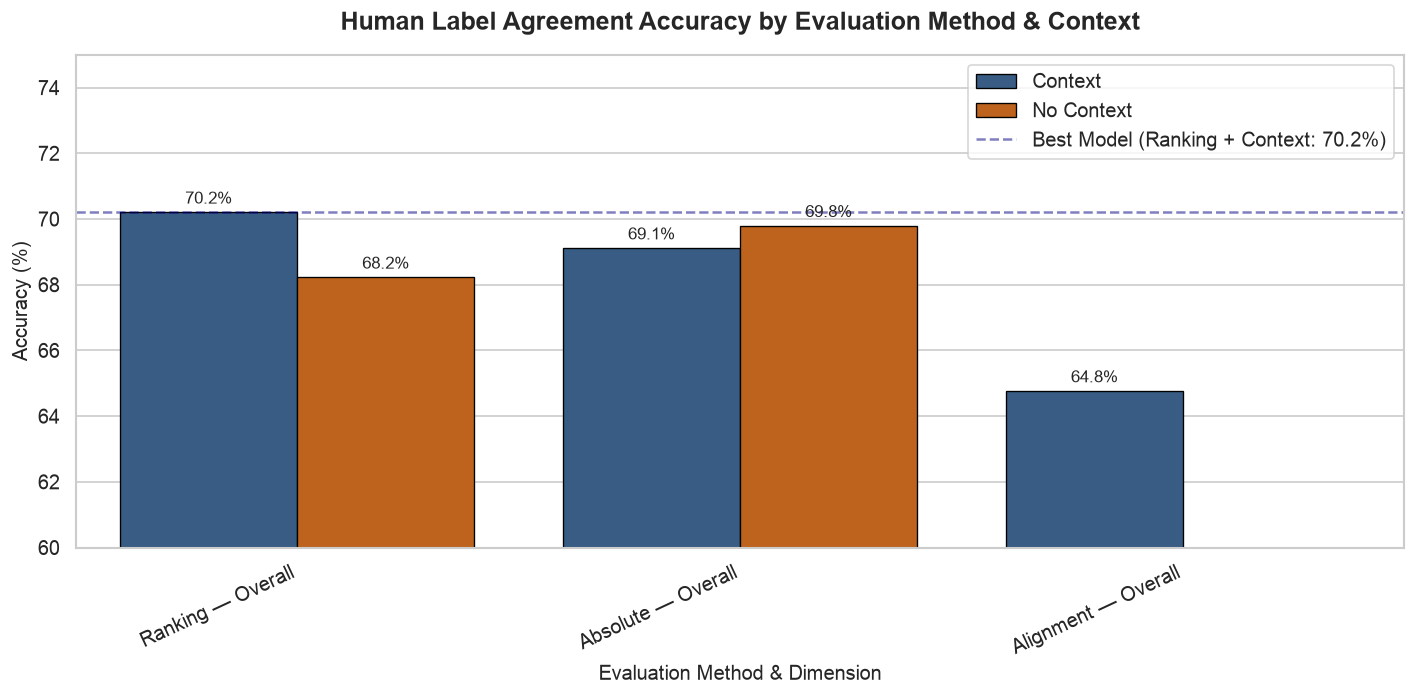

In [11]:
# Bar chart comparing human agreement accuracy across all models and context conditions
fig, ax = plt.subplots(figsize=(12, 6))

plot_summary = summary_table[summary_table["Dimension"]=="Overall"].copy()
plot_summary["Model_Dim"] = plot_summary["Method"].str.split(" ").str[0] + " — " + plot_summary["Dimension"]

sns.barplot(
    data=plot_summary,
    x="Model_Dim",
    y="Accuracy (%)",
    hue="Context",
    palette={"Context": "#2b5c8f", "No Context": "#d95f02"},
    ax=ax,
    edgecolor="black",
    linewidth=0.8
)

ax.set_title("Human Label Agreement Accuracy by Evaluation Method & Context", fontsize=15, fontweight="bold", pad=15)
ax.set_ylabel("Accuracy (%)", fontsize=12)
ax.set_xlabel("Evaluation Method & Dimension", fontsize=12)
ax.set_ylim(60, 75)
ax.axhline(70.21, color="navy", linestyle="--", alpha=0.5, label="Best Model (Ranking + Context: 70.2%)")
ax.legend(loc="upper right", frameon=True)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.1f}%", (p.get_x() + p.get_width() / 2., height),
                    ha="center", va="bottom", fontsize=10, xytext=(0, 3), textcoords="offset points")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


### Probability of Human Agreement vs. Ideological Distance (as in `pca.ipynb`)
Evaluate calibration: As the predicted ideological distance $|s_{\text{top}} - s_{\text{bottom}}|$ between two videos increases, does human agreement probability scale towards 1.0?


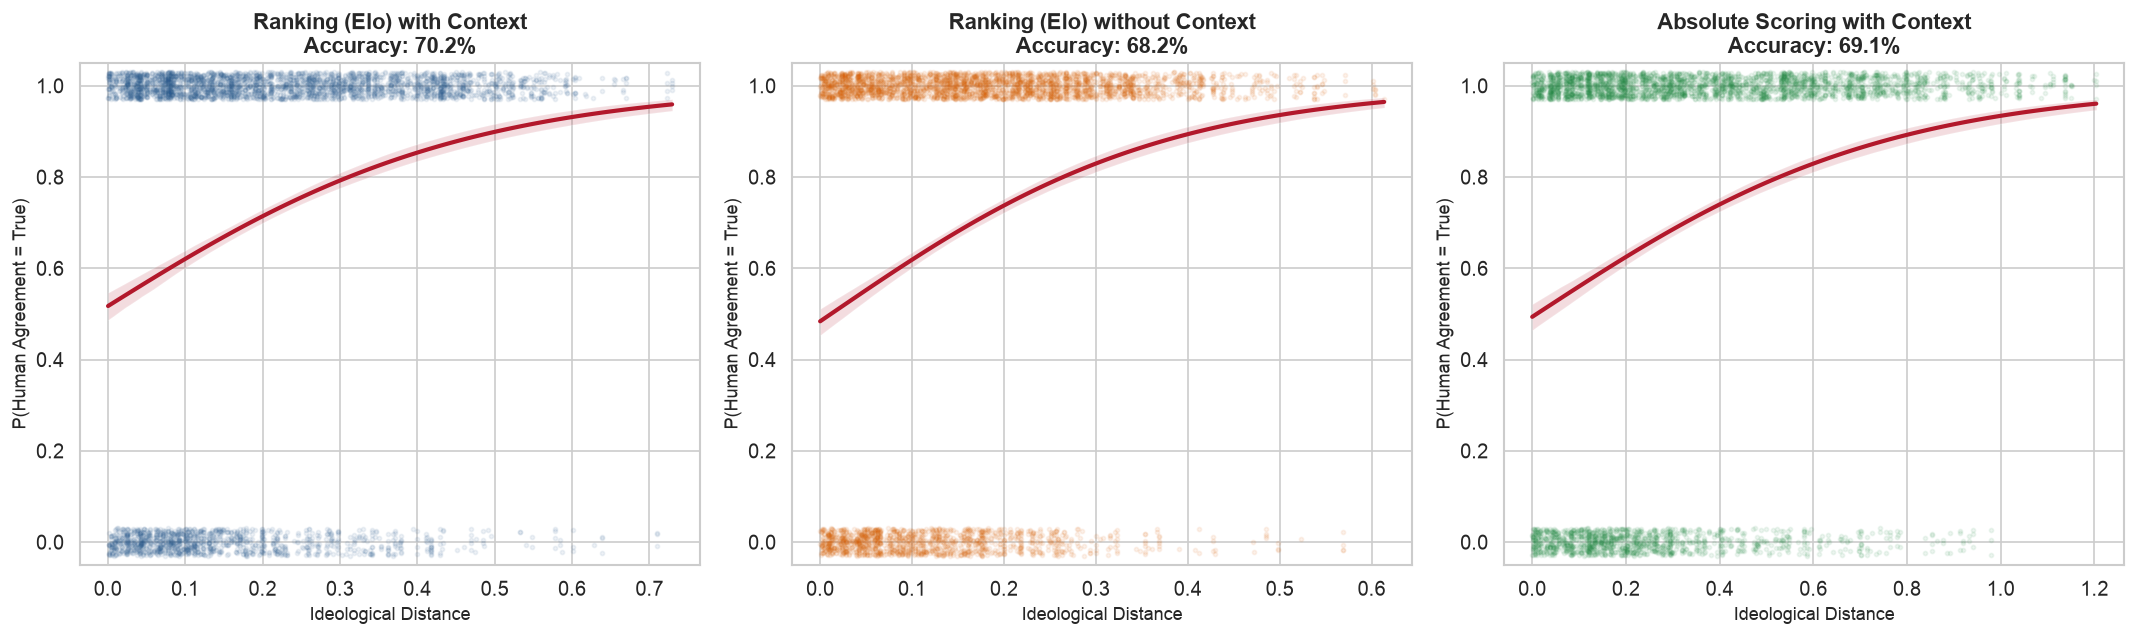

In [9]:
# Logistic regression: Probability of Agreement vs. Predicted Distance (matching pca.ipynb methodology)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

models_to_plot = [
    ("ranking_context_overall", "Ranking (Elo) with Context", "#2b5c8f", axes[0]),
    ("ranking_no_context_overall", "Ranking (Elo) without Context", "#d95f02", axes[1]),
    ("absolute_context_overall", "Absolute Scoring with Context", "#238b45", axes[2])
]

for key, title, scatter_col, ax in models_to_plot:
    df_plot = all_evaluations[key]["df_eval"]
    acc = all_evaluations[key]["accuracy"]
    sns.regplot(
        data=df_plot,
        x="dist",
        y="agree",
        logistic=True,
        ci=95,
        scatter_kws={"s": 6, "alpha": 0.08, "color": scatter_col},
        line_kws={"color": "#b2182b", "linewidth": 2.5},
        y_jitter=0.03,
        ax=ax
    )
    ax.set_title(f"{title}\nAccuracy: {acc:.1%}", fontsize=13, fontweight="bold")
    ax.set_ylabel("P(Human Agreement = True)", fontsize=11)
    ax.set_xlabel("Ideological Distance", fontsize=11)
    ax.set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.show()
